In [18]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd
import numpy as np

In [19]:
df = pd.read_csv('chartg.csv')
df.head(15)

,Task,Start,Finish,Duration
0,Project development,2026-10-01,2027-06-05,177
1,Review online resources,2026-10-01,2027-02-01,88
2,Analysis results from literature,2026-11-01,2027-02-01,66
3,"Searching dataset, Q&A",2026-10-01,2027-01-01,67
4,Data preparation and Analysis,2026-12-01,2027-01-01,24
5,Collection data from local shops,2026-12-01,2027-02-01,45
6,ML modelling,2027-02-01,2027-03-01,21
7,Analysis and ML from Q&A,2027-02-01,2027-04-01,44
8,Analysis results of datasets,2027-02-01,2027-04-01,44
9,Strategic recommendations,2027-04-01,2027-06-01,44


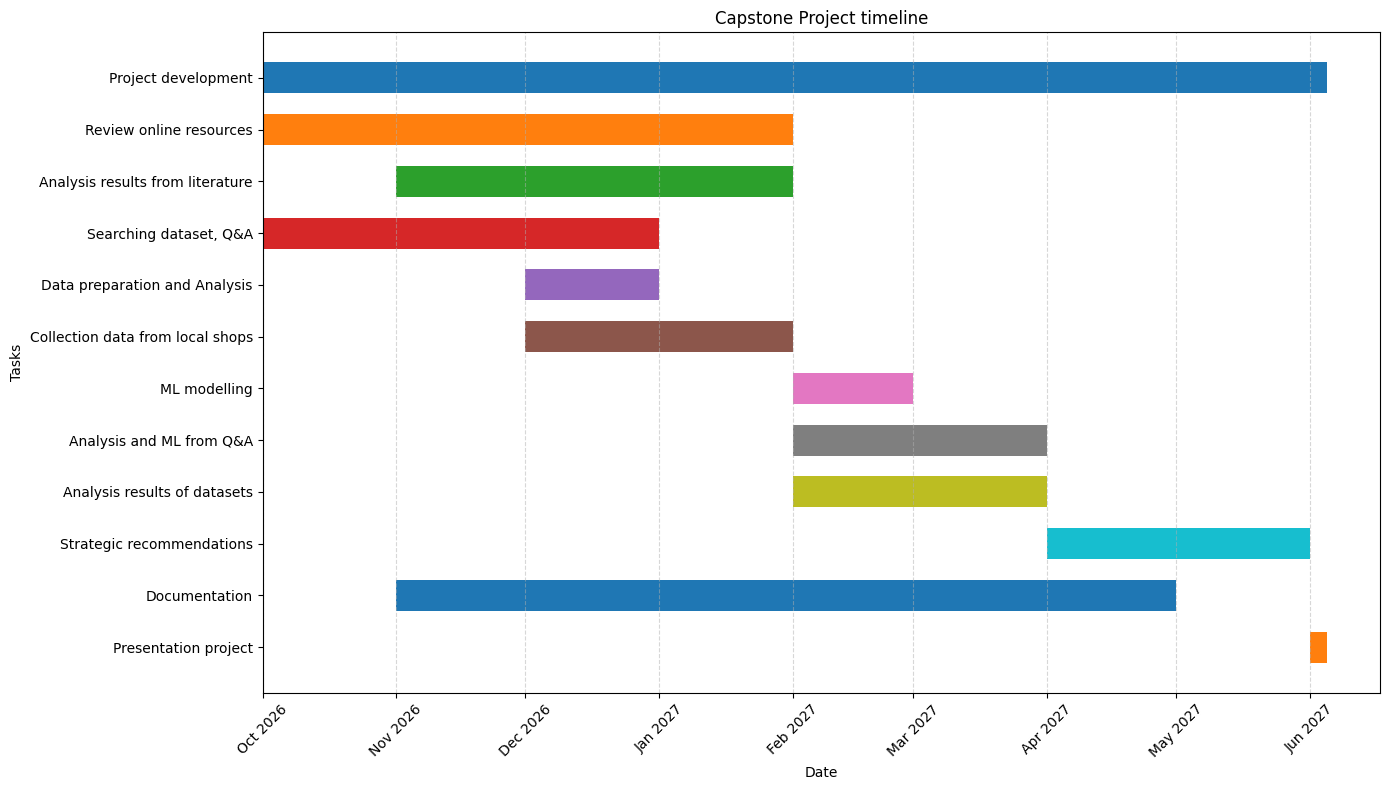

In [21]:
# Convert dates
df["Start"] = pd.to_datetime(df["Start"])
df["Finish"] = pd.to_datetime(df["Finish"])

# Calculate duration from dates
df["Duration"] = (df["Finish"] - df["Start"]).dt.days

# Create chart
fig, ax = plt.subplots(figsize=(14, 8))

for i, row in df.iterrows():
    ax.barh(
        y=i,
        width=row["Duration"],
        left=mdates.date2num(row["Start"]),
        height=0.6
    )

# Configure tasks and dates
ax.set_yticks(range(len(df)))
ax.set_yticklabels(df["Task"])
ax.invert_yaxis()

ax.xaxis_date()
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%b %Y")
)

ax.set_xlabel("Date")
ax.set_ylabel("Tasks")
ax.set_title("Capstone Project timeline")

plt.xticks(rotation=45)
ax.grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()

# Save chart
plt.savefig("Projecttimeline.png", dpi=300)

plt.show()